# Geopandas Experimentation : Rhode Island

- Experimenting with code provided by Frank Donnelly Head of GIS and Data Services from the Brown University Library in order to develop geopandas understanding! link to the original repository here : https://github.com/Brown-University-Library/geodata_geopandas_basic
- Using data regarding rhode island of the USA : ESPG codes found here https://epsg.io/ 
- Annotating the functions to deepen my ability reading code 

## Import libaries 

- Import %matplotlib inline to plot inwith notebook

In [1]:
import os
import pandas as pd
import geopandas as gpd
from shapely.geometry import LineString
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Read Input and Create Geometry From Points

In [2]:
# Read shapefile
county_file=os.path.join('D:/GitHub/geodata_geopandas_basic-main/input/ri_county_bndy.shp')
gdf_cnty=gpd.read_file(county_file)
gdf_cnty.head() 
## .head fucntion tells python to display only first 5 rows of a table 

,statefp,countyfp,countyns,geoid,name,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,funcstat,aland,awater,intptlat,intptlon,geometry
0,44,009,01219782,44009,Washington,Washington County,06,H4,G4020,148,39300,N,852827571,604769755,+41.3967920,-071.6202820,"MULTIPOLYGON (((307427.031 86583.659, 307412.2..."
1,44,007,01219781,44007,Providence,Providence County,06,H4,G4020,148,39300,N,1060552463,67870199,+41.8697678,-071.5786246,"POLYGON ((315157.916 236069.733, 315138.271 23..."
2,44,001,01219777,44001,Bristol,Bristol County,06,H4,G4020,148,39300,N,62500772,53359134,+41.7068397,-071.2866874,"POLYGON ((407177.244 220459.551, 407060.698 22..."
3,44,005,01219779,44005,Newport,Newport County,06,H4,G4020,148,39300,N,265293780,547001789,+41.5010449,-071.2830626,"POLYGON ((433188.859 146428.981, 433458.478 14..."
4,44,003,01219778,44003,Kent,Kent County,06,H4,G4020,148,39300,N,436588773,50686111,+41.6751180,-071.5802819,"POLYGON ((315828.392 188986.602, 315772.035 18..."


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

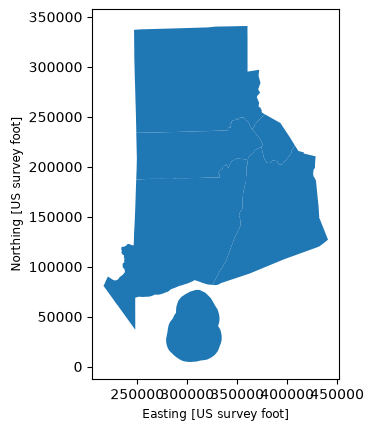

In [3]:
# Basic plot with GeoPandas
gdf_cnty.plot()

In [4]:
# Read CSV file
point_file=os.path.join('D:/GitHub/geodata_geopandas_basic-main/input/test_points.csv') # loading file in from directory

df_pnts=pd.read_csv(point_file, index_col='OBS_NUM', delimiter=',',dtype={'GEOID':str}) #defining the data, sets the collumn OBS_NUM as the row of the pandas data frame, specifying that seperations come from ',', and that the GeoID is to remain a string.

gdf_pnts = gpd.GeoDataFrame(df_pnts,geometry=gpd.points_from_xy(
    df_pnts['INTPTLONG'],df_pnts['INTPTLAT']),crs = 'EPSG:4269')
# converting pandas data frame into a spatial geodata frame
# creates point geomtry objects using long/lat (intplong/intplat) as X and Y co-ords
# crs=co-ord reference system used by data set
gdf_pnts

,OBS_NAME,GROUP,OBS_DATE,GEOID,NAME,USPS,ALAND_SQMI,AWATER_SQMI,INTPTLAT,INTPTLONG,geometry
OBS_NUM,,,,,,,,,,,
0,alfa,a,1/5/2020,4414140,Central Falls city,RI,1.194,0.080,41.890064,-71.393481,POINT (-71.39348 41.89006)
1,bravo,a,1/31/2020,4419180,Cranston city,RI,28.345,1.672,41.769734,-71.485049,POINT (-71.48505 41.76973)
2,charlie,a,1/15/2020,4422960,East Providence city,RI,13.284,3.322,41.800433,-71.359258,POINT (-71.35926 41.80043)
3,delta,a,2/10/2020,4449960,Newport city,RI,7.656,3.718,41.476681,-71.319627,POINT (-71.31963 41.47668)
4,echo,a,2/5/2020,4454640,Pawtucket city,RI,8.667,0.297,41.874824,-71.373323,POINT (-71.37332 41.87482)
5,foxtrot,a,1/15/2020,4459000,Providence city,RI,18.406,2.179,41.823056,-71.418784,POINT (-71.41878 41.82306)
6,golf,b,1/16/2020,4459000,Providence city,RI,18.406,2.179,41.823056,-71.418784,POINT (-71.41878 41.82306)
7,hotel,b,1/31/2020,4474300,Warwick city,RI,35.001,14.750,41.703085,-71.420310,POINT (-71.42031 41.70308)
8,india,b,2/1/2020,4480780,Woonsocket city,RI,7.746,0.194,42.001708,-71.499947,POINT (-71.49995 42.00171)


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

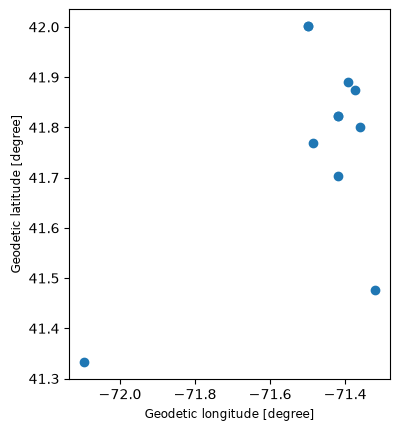

In [5]:
gdf_pnts.plot() #plotting this data long/lat

# 2. Get CRS Info and Transform

Investigating the Coordinate Reference Systems (CRS) and spatial extents (bounding boxes) of the two GeoPandas data frames: gdf_cnty (counties) and gdf_pnts (points) and transforming them so the CRS remains consistent 

In [7]:
# CRS Counties (Co-ordinate reference system) 
gdf_cnty.crs

<Projected CRS: EPSG:3438>
Name: NAD83 / Rhode Island (ftUS)
Axis Info [cartesian]:
- X[east]: Easting (US survey foot)
- Y[north]: Northing (US survey foot)
Area of Use:
- name: United States (USA) - Rhode Island - counties of Bristol; Kent; Newport; Providence; Washington.
- bounds: (-71.85, 41.13, -71.08, 42.02)
Coordinate Operation:
- name: SPCS83 Rhode Island zone (US survey foot)
- method: Transverse Mercator
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [8]:
# Bounds Counties
gdf_cnty.total_bounds

array([216185.97680585,   4568.47853844, 440907.38505165, 340888.89765888])

In [9]:
# CRS Points
gdf_pnts.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada. Puerto Rico. United States (USA). US Virgin Islands. British Virgin Islands.
- bounds: (167.65, 14.92, -40.73, 86.46)
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

pnts. CRS differes to the CRS of the county !

In [10]:
# Bounds Points
gdf_pnts.total_bounds

array([-72.096176,  41.332957, -71.319627,  42.001708])

Transform Point Geometry to Match County CRS

In [11]:
# Transform Point Geometry to Match County CRS
# 3438 is the EPSG for for the RI State Plane Zone
gdf_pnts.to_crs(3438,inplace=True) #.to_crs is taking the data set and reprojecting the data availble into a new co-ord system using the EPSG registry system for rhode island, inplace=true tells pandas to modify current data frame rather than create a copy
gdf_pnts.crs #verification of new CRS

<Projected CRS: EPSG:3438>
Name: NAD83 / Rhode Island (ftUS)
Axis Info [cartesian]:
- X[east]: Easting (US survey foot)
- Y[north]: Northing (US survey foot)
Area of Use:
- name: United States (USA) - Rhode Island - counties of Bristol; Kent; Newport; Providence; Washington.
- bounds: (-71.85, 41.13, -71.08, 42.02)
Coordinate Operation:
- name: SPCS83 Rhode Island zone (US survey foot)
- method: Transverse Mercator
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

'total.bounds' calculates the spatial extent of all of the points within this data frame (the total bounds, also known as abounding box). Should return a array representing the minimum and maximum coordinates: [xmin, ymin, xmax, ymax] 

In [12]:
gdf_pnts.total_bounds

array([164350.33557909,  91515.54713867, 377511.59607262, 334638.78150084])

Plotting this data as a map

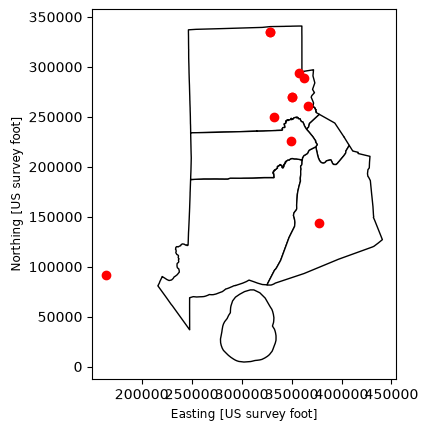

In [13]:
basemap = gdf_cnty.plot(color='white', edgecolor='black') #creating a base layer using the gdf_cnty boundaries, the color=white creates white polgygon, and edgecolour sets the edges of the pologon to be black
#saving as 'basemap' stores as a matplotlib object so you can add additional layers on top 
gdf_pnts.plot(ax=basemap, color='red'); #plots the point data ontop of the object just created, ax=basemap ensures plot atop of the previously created pologon, and colour=red specifies the colour of the dots

# 3. Spatial Join Points and Polygons

Keep all points on left, null values for non-matching counties on right. 
Take subset of columns from right, must always include geom for spatial joins.

In [15]:
gdf_pnts_wcnty=gpd.sjoin(gdf_pnts, gdf_cnty[['geoid','namelsad','geometry']],
                         how='left', predicate='intersects')
#creates new data frame to store the results, gpd.sjoin is the spatial fucntion combining results base on thier geographic location rather than ID, GDF_pnts is the left data set countaining points
#gdf_cnty[['geoid','namelsad','geometry' is the right data set of polygons using only three collumns, how=left specfies a 'left join' which means all points are kept within data set even if they fall outwith the county, predicate='intersects' checks whether a point intersects (falls within or touches) a county polygon.
gdf_pnts_wcnty.rename(columns={'geoid': 'COUNTY_ID', 'namelsad': 'COUNTY'}, inplace=True) #renaming the collumns, inplace = true modifies the current dataframe
gdf_pnts_wcnty.loc[:,['OBS_NAME','OBS_DATE','COUNTY']] #.loc[:, [...]: pandas indexing method used to filter or select rows and columns by label, '[:,' colon before the comma means "select all rows", ['OBS_NAME', 'OBS_DATE', 'COUNTY'] list of specific columns kept in the final output.

,OBS_NAME,OBS_DATE,COUNTY
OBS_NUM,,,
0,alfa,1/5/2020,Providence County
1,bravo,1/31/2020,Providence County
2,charlie,1/15/2020,Providence County
3,delta,2/10/2020,Newport County
4,echo,2/5/2020,Providence County
5,foxtrot,1/15/2020,Providence County
6,golf,1/16/2020,Providence County
7,hotel,1/31/2020,Kent County
8,india,2/1/2020,Providence County


Counting the number of points within each polygon

In [16]:
cnty_count=gdf_pnts_wcnty.groupby(['COUNTY_ID','COUNTY'],dropna=False).agg(numpoints=('COUNTY_ID', 'count'))
#define new count, groups by then groups the rows of the data frame sharing county ID and name, dropna=false allows points not within a county still to be grouped? 
#.agg creates an aggreation, a calculation called 'numpoints', creates a column counting how many times countyID appears in each group
cnty_count #displays data

,,numpoints
COUNTY_ID,COUNTY,
44003,Kent County,1
44005,Newport County,1
44007,Providence County,8
NaN,NaN,0


# 4. Generate Lines from Points Grouped by Categories and Calculate Length

Assumes points are in proper sequence; if not, sort by sequence column first. Output measurement units are based on the CRS.

In [18]:
lines = gdf_pnts.groupby('GROUP')['geometry'].apply(lambda x: LineString(x.tolist()))
#.groupby('GROUP') groups the dataset rows together based on the values found in a column named 'GROUP'.['geometry'], isolates just the geometry column for each group
#.apply(...): applies a custom operation to each group.
#lambda x: LineString(x.tolist()): function where x represents the collection of points in a given group. x.tolist() converts those points into a list, and LineString(...) connects them in order to form a continuous line geometry.
gdf_lines = gpd.GeoDataFrame(lines, geometry='geometry',crs = 'EPSG:3438').reset_index()
#gpd.GeoDataFrame(lines, ...) converts lines into a brand-new GeoPandas GeoDataFrame.
#geometry='geometry' tells GeoPandas which column contains the spatial geometry data.
#crs='EPSG:3438' setting CRS
#.reset_index(): takes the 'GROUP' identifier (which was turned into an index by the groupby operation) and converts it back into a regular column in the table.
gdf_lines['length_mi']=(gdf_lines.length)/5280
#converting length from feet to miles, gfd_lines.length function calculates the length of lines in feet
gdf_lines.loc[:,['GROUP','length_mi']]

,GROUP,length_mi
0,a,70.718183
1,b,29.295344
2,c,55.516051


# 5. Plot map, points, and lines grouped using matplotlib

Use matplotlib to plot these lines and the points within the county polygon 

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

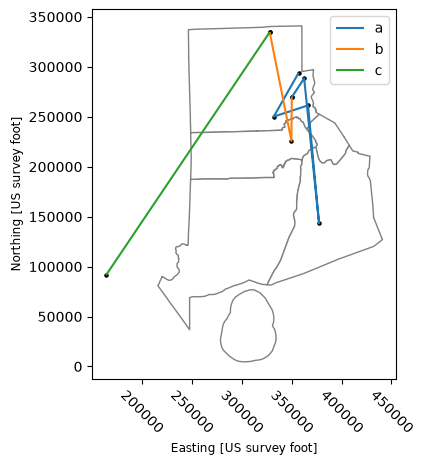

In [21]:
fig, ax = plt.subplots() #fig creates a new figure, ax creates a new set of axes/subplots ensuring all remains on one figure
plt.xticks(rotation=315) #rotates labels on X axis by -45 degrees
gdf_cnty.plot(ax=ax, color='white', edgecolor='grey') #plotting basemap as above
gdf_pnts.plot(ax=ax,color='black', markersize=5)
gdf_lines.plot(ax=ax, column="GROUP", legend=True)
#plots the GeoDataFrame of line data (gdf_lines), column="GROUP" color-codes the lines automatically based on the categories or values found in the "GROUP" column of your data, legend=True generates and displays a color legend on the side of the map to explain what each line color represents.

# 6. WRITE OUTPUT

In [24]:
out_points=os.path.join('D:/GitHub/geodata_geopandas_basic-main/test_pnts_counties_ri.shp')
out_lines=os.path.join('D:/GitHub/geodata_geopandas_basic-main/test_lines_ri.shp')

gdf_pnts_wcnty.to_file(out_points)
gdf_lines.to_file(out_lines)

C:\Users\2455292P\AppData\Local\Temp\ipykernel_19672\688750480.py:4: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf_pnts_wcnty.to_file(out_points)
C:\Users\2455292P\AppData\Local\anaconda3\envs\geo_env\lib\python\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'AWATER_SQMI' to 'AWATER_SQM'
  ogr_write(
C:\Users\2455292P\AppData\Local\anaconda3\envs\geo_env\lib\python\site-packages\pyogrio\raw.py:733: RuntimeWarning: Normalized/laundered field name: 'index_right' to 'index_righ'
  ogr_write(
